<a href="https://colab.research.google.com/github/arielsharonferdinandus/attention_transformer/blob/main/attention_transformer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning: Attention dan Blok Transformer Sederhana

Notebook ini dapat dijalankan langsung di Google Colab (**Runtime → Run all**). Semua eksperimen kecil sehingga CPU sudah cukup.

**Daftar isi**
0. Setup
1. Scaled dot-product attention (hitung manual vs program)
2. Multi-head attention (d_model = 8, h = 2) dan jumlah parameter
3. Masking (padding mask dan causal mask)
4. Sinusoidal positional encoding
5. Blok transformer (MHA + FFN + residual + LayerNorm)
6. Uji fungsional: klasifikasi sekuens dua kelas
7. Verifikasi implementasi (shape, parameter, softmax, mask, overfit satu batch)
8. Jawaban pertanyaan analisis 1 sampai 9

## 0. Setup

In [1]:
import math, random
import numpy as np
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt

SEED = 42
def set_seed(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)

set_seed()
torch.set_printoptions(precision=4, sci_mode=False, linewidth=140)
print("PyTorch:", torch.__version__)

PyTorch: 2.11.0+cpu


## 1. Scaled Dot-Product Attention

$$\text{Attention}(Q,K,V)=\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)V$$

Data: $q=[1,0,1,0]$, $k_1=[1,0,0,0]$, $k_2=[0,1,0,0]$, $v_1=[1,0]$, $v_2=[0,1]$, sehingga $d_k=4$ dan $\sqrt{d_k}=2$.

### Perhitungan manual

1. Skor mentah: $q\cdot k_1 = 1\cdot1+0\cdot0+1\cdot0+0\cdot0 = 1$ dan $q\cdot k_2 = 1\cdot0+0\cdot1+1\cdot0+0\cdot0 = 0$.
2. Skala: $s_1 = 1/2 = 0{,}5$ dan $s_2 = 0/2 = 0$.
3. Softmax: $e^{0,5}=1{,}6487$ dan $e^{0}=1$, jumlah $=2{,}6487$.
   - $w_1 = 1{,}6487/2{,}6487 = 0{,}6225$
   - $w_2 = 1/2{,}6487 = 0{,}3775$
4. Keluaran: $o = w_1 v_1 + w_2 v_2 = 0{,}6225\,[1,0] + 0{,}3775\,[0,1] = [0{,}6225,\ 0{,}3775]$.

In [2]:
def scaled_dot_product_attention(q, k, v, mask=None):
    # q,k,v: (..., T, d). mask boolean broadcastable ke (..., Tq, Tk), True = BOLEH diperhatikan.
    d_k = q.size(-1)
    scores = q @ k.transpose(-2, -1) / math.sqrt(d_k)
    if mask is not None:
        scores = scores.masked_fill(~mask, float("-inf"))
    w = torch.softmax(scores, dim=-1)
    w = torch.nan_to_num(w, nan=0.0)       # baris tanpa posisi valid -> 0, bukan NaN
    return w @ v, w, scores

q = torch.tensor([[1., 0., 1., 0.]])
K = torch.tensor([[1., 0., 0., 0.], [0., 1., 0., 0.]])
V = torch.tensor([[1., 0.], [0., 1.]])

out, w, s = scaled_dot_product_attention(q, K, V)

# ---- perhitungan manual (tanpa library tensor)
d_k = 4
dot = [1*1 + 0*0 + 1*0 + 0*0,  1*0 + 0*1 + 1*0 + 0*0]      # [1, 0]
sc  = [d / math.sqrt(d_k) for d in dot]                      # [0.5, 0]
ex  = [math.exp(x) for x in sc]
w_manual = [e / sum(ex) for e in ex]
o_manual = [w_manual[0]*1 + w_manual[1]*0, w_manual[0]*0 + w_manual[1]*1]

print("skor mentah        :", dot)
print("skor terskala      :", sc)
print("bobot manual       :", [round(x, 4) for x in w_manual])
print("bobot program      :", w.squeeze().tolist())
print("keluaran manual    :", [round(x, 4) for x in o_manual])
print("keluaran program   :", out.squeeze().tolist())

assert torch.allclose(w.squeeze(), torch.tensor(w_manual), atol=1e-6)
assert torch.allclose(out.squeeze(), torch.tensor(o_manual), atol=1e-6)
assert abs(o_manual[0] - 0.6225) < 1e-4 and abs(o_manual[1] - 0.3775) < 1e-4   # angka di derivasi tertulis
print("\nOK: hasil program = hasil manual = [0.6225, 0.3775]")

skor mentah        : [1, 0]
skor terskala      : [0.5, 0.0]
bobot manual       : [0.6225, 0.3775]
bobot program      : [0.622459352016449, 0.3775406777858734]
keluaran manual    : [0.6225, 0.3775]
keluaran program   : [0.622459352016449, 0.3775406777858734]

OK: hasil program = hasil manual = [0.6225, 0.3775]


## 2. Multi-Head Attention (d_model = 8, h = 2)

Setiap head memakai $d_k = d_v = d_{model}/h = 4$. Ada empat proyeksi linear $W_Q, W_K, W_V, W_O$, masing-masing $8\times8$ dengan bias.

### Jumlah parameter (manual)

| Proyeksi | Bobot | Bias | Total |
|---|---|---|---|
| $W_Q$ | 8×8 = 64 | 8 | 72 |
| $W_K$ | 64 | 8 | 72 |
| $W_V$ | 64 | 8 | 72 |
| $W_O$ | 64 | 8 | 72 |
| **Total** | 256 | 32 | **288** |

In [3]:
class MultiHeadAttention(nn.Module):
    def __init__(self, d_model=8, h=2):
        super().__init__()
        assert d_model % h == 0
        self.d_model, self.h, self.d_k = d_model, h, d_model // h
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)
        self.W_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):                       # (B,T,d_model) -> (B,h,T,d_k)
        B, T, _ = x.shape
        return x.view(B, T, self.h, self.d_k).transpose(1, 2)

    def forward(self, x, mask=None):
        B, T, _ = x.shape
        q, k, v = (self.split_heads(l(x)) for l in (self.W_q, self.W_k, self.W_v))
        out, w, _ = scaled_dot_product_attention(q, k, v, mask)   # out (B,h,T,d_k), w (B,h,T,T)
        out = out.transpose(1, 2).contiguous().view(B, T, self.d_model)
        return self.W_o(out), w

set_seed()
mha = MultiHeadAttention(8, 2)

manual_params = 4 * (8 * 8 + 8)
program_params = sum(p.numel() for p in mha.parameters())
print("Parameter manual  :", manual_params)
print("Parameter program :", program_params)
for n, p in mha.named_parameters():
    print(f"  {n:12s} {tuple(p.shape)!s:10s} {p.numel()}")
assert manual_params == program_params == 288
print("OK: 288 = 288")

Parameter manual  : 288
Parameter program : 288
  W_q.weight   (8, 8)     64
  W_q.bias     (8,)       8
  W_k.weight   (8, 8)     64
  W_k.bias     (8,)       8
  W_v.weight   (8, 8)     64
  W_v.bias     (8,)       8
  W_o.weight   (8, 8)     64
  W_o.bias     (8,)       8
OK: 288 = 288


Verifikasi independen: salin bobot ke `nn.MultiheadAttention` bawaan PyTorch, lalu bandingkan keluaran dan bobot attention per head.

In [4]:
ref = nn.MultiheadAttention(8, 2, batch_first=True)
with torch.no_grad():
    ref.in_proj_weight.copy_(torch.cat([mha.W_q.weight, mha.W_k.weight, mha.W_v.weight], 0))
    ref.in_proj_bias.copy_(torch.cat([mha.W_q.bias, mha.W_k.bias, mha.W_v.bias], 0))
    ref.out_proj.weight.copy_(mha.W_o.weight); ref.out_proj.bias.copy_(mha.W_o.bias)

set_seed()
x = torch.randn(2, 4, 8)
y, w_ours = mha(x)
y_ref, w_ref = ref(x, x, x, need_weights=True, average_attn_weights=False)
print("keluaran   :", tuple(y.shape), " max|selisih| =", (y - y_ref).abs().max().item())
print("bobot attn :", tuple(w_ours.shape), " max|selisih| =", (w_ours - w_ref).abs().max().item())
assert torch.allclose(y, y_ref, atol=1e-5) and torch.allclose(w_ours, w_ref, atol=1e-5)

# dengan causal mask
T = 4
causal_bool = torch.tril(torch.ones(T, T, dtype=torch.bool))
y_c, w_c = mha(x, causal_bool[None, None])
y_cr, w_cr = ref(x, x, x, attn_mask=~causal_bool, need_weights=True, average_attn_weights=False)  # di nn.MHA True = DILARANG
assert torch.allclose(y_c, y_cr, atol=1e-5) and torch.allclose(w_c, w_cr, atol=1e-5)
print("OK: implementasi MHA sama dengan nn.MultiheadAttention (tanpa dan dengan causal mask)")

keluaran   : (2, 4, 8)  max|selisih| = 1.1920928955078125e-07
bobot attn : (2, 2, 4, 4)  max|selisih| = 5.960464477539063e-08
OK: implementasi MHA sama dengan nn.MultiheadAttention (tanpa dan dengan causal mask)


## 3. Masking

Konvensi di notebook ini: mask boolean, **True = posisi boleh diperhatikan**. Posisi terlarang diisi $-\infty$ sebelum softmax, sehingga bobotnya tepat 0 setelah softmax.

- **Padding mask** `(B,1,1,T)`: key yang berupa token PAD tidak boleh diperhatikan.
- **Causal mask** `(1,1,T,T)`: segitiga bawah, posisi $i$ hanya boleh melihat $j \le i$.

In [5]:
def make_padding_mask(lengths, T):                 # (B,1,1,T), True = key valid
    idx = torch.arange(T)[None, :]
    return (idx < lengths[:, None])[:, None, None, :]

def make_causal_mask(T):                           # (1,1,T,T), True = boleh
    return torch.tril(torch.ones(T, T, dtype=torch.bool))[None, None]

B, T = 2, 4
lengths = torch.tensor([4, 2])                     # sampel ke-1 punya 2 token valid + 2 PAD
pad_mask, causal = make_padding_mask(lengths, T), make_causal_mask(T)
set_seed()
x = torch.randn(B, T, 8)

for name, m in [("padding", pad_mask), ("causal", causal), ("padding + causal", pad_mask & causal)]:
    _, w = mha(x, m)
    allowed = m.expand(B, mha.h, T, T)
    forbidden = ~allowed
    print(f"=== {name} mask ===  (sampel ke-1, head 0)")
    print("mask (1=boleh):\n", allowed[1, 0].int())
    print("bobot attention:\n", w[1, 0])
    print("bobot pada posisi terlarang:", w[forbidden].unique().tolist())
    assert (w[forbidden] == 0).all(), "ada bobot nonzero di posisi terlarang!"
    row_valid = allowed.any(-1)
    assert torch.allclose(w.sum(-1)[row_valid], torch.ones_like(w.sum(-1)[row_valid]), atol=1e-6)
    print("OK: bobot terlarang = 0 dan setiap baris valid berjumlah 1\n")

=== padding mask ===  (sampel ke-1, head 0)
mask (1=boleh):
 tensor([[1, 1, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 0, 0]], dtype=torch.int32)
bobot attention:
 tensor([[0.4710, 0.5290, 0.0000, 0.0000],
        [0.3409, 0.6591, 0.0000, 0.0000],
        [0.5231, 0.4769, 0.0000, 0.0000],
        [0.4789, 0.5211, 0.0000, 0.0000]], grad_fn=<SelectBackward0>)
bobot pada posisi terlarang: [0.0]
OK: bobot terlarang = 0 dan setiap baris valid berjumlah 1

=== causal mask ===  (sampel ke-1, head 0)
mask (1=boleh):
 tensor([[1, 0, 0, 0],
        [1, 1, 0, 0],
        [1, 1, 1, 0],
        [1, 1, 1, 1]], dtype=torch.int32)
bobot attention:
 tensor([[1.0000, 0.0000, 0.0000, 0.0000],
        [0.3409, 0.6591, 0.0000, 0.0000],
        [0.3583, 0.3267, 0.3150, 0.0000],
        [0.1934, 0.2105, 0.1697, 0.4264]], grad_fn=<SelectBackward0>)
bobot pada posisi terlarang: [0.0]
OK: bobot terlarang = 0 dan setiap baris valid berjumlah 1

=== padding + causal mask ===  (sampel ke-1, 

### Kasus tepi: baris yang seluruh posisinya terlarang

Pada implementasi naif, `softmax` dari baris yang semuanya $-\infty$ menghasilkan **NaN** (0/0). Kesalahan ini memang mudah muncul pada versi pertama kode attention. Perbaikannya ada pada `scaled_dot_product_attention` di atas (`nan_to_num`), dan diverifikasi di bawah.

In [6]:
def naive_attention_weights(q, k, mask):          # versi NAIF (punya bug untuk baris fully-masked)
    s = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
    return torch.softmax(s.masked_fill(~mask, float("-inf")), -1)

set_seed()
qq = torch.randn(1, 3, 4); kk = torch.randn(1, 3, 4); vv = torch.randn(1, 3, 4)
m = torch.tensor([[[False, False, False],       # baris 0: tidak ada posisi valid
                   [True,  False, False],
                   [True,  True,  False]]])

w_bug = naive_attention_weights(qq, kk, m)
_, w_fix, _ = scaled_dot_product_attention(qq, kk, vv, m)
print("naif :\n", w_bug, "\n -> mengandung NaN:", torch.isnan(w_bug).any().item())
print("\nperbaikan:\n", w_fix, "\n -> mengandung NaN:", torch.isnan(w_fix).any().item())

assert torch.isnan(w_bug).any() and not torch.isnan(w_fix).any()
rows_valid = m.any(-1)
assert torch.allclose(w_fix.sum(-1)[rows_valid], torch.ones(2), atol=1e-6)   # baris valid tetap berjumlah 1
assert (w_fix[~rows_valid] == 0).all()                                      # baris tanpa posisi valid = 0
print("\nOK: baris valid berjumlah 1; baris tanpa posisi valid bernilai 0 tanpa NaN")

naif :
 tensor([[[   nan,    nan,    nan],
         [1.0000, 0.0000, 0.0000],
         [0.5616, 0.4384, 0.0000]]]) 
 -> mengandung NaN: True

perbaikan:
 tensor([[[0.0000, 0.0000, 0.0000],
         [1.0000, 0.0000, 0.0000],
         [0.5616, 0.4384, 0.0000]]]) 
 -> mengandung NaN: False

OK: baris valid berjumlah 1; baris tanpa posisi valid bernilai 0 tanpa NaN


## 4. Sinusoidal Positional Encoding

$$PE_{(pos,2i)}=\sin\!\left(\frac{pos}{10000^{2i/d_{model}}}\right),\qquad PE_{(pos,2i+1)}=\cos\!\left(\frac{pos}{10000^{2i/d_{model}}}\right)$$

shape PE (T=4, d_model=8): (4, 8) | buffer penuh: (1, 64, 8)
tensor([[ 0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000,  0.0000,  1.0000],
        [ 0.8415,  0.5403,  0.0998,  0.9950,  0.0100,  0.9999,  0.0010,  1.0000],
        [ 0.9093, -0.4161,  0.1987,  0.9801,  0.0200,  0.9998,  0.0020,  1.0000],
        [ 0.1411, -0.9900,  0.2955,  0.9553,  0.0300,  0.9996,  0.0030,  1.0000]])

OK: nilai PE sama dengan rumus (pos=0 dan pos=1)
shape setelah x + PE: (2, 4, 8)


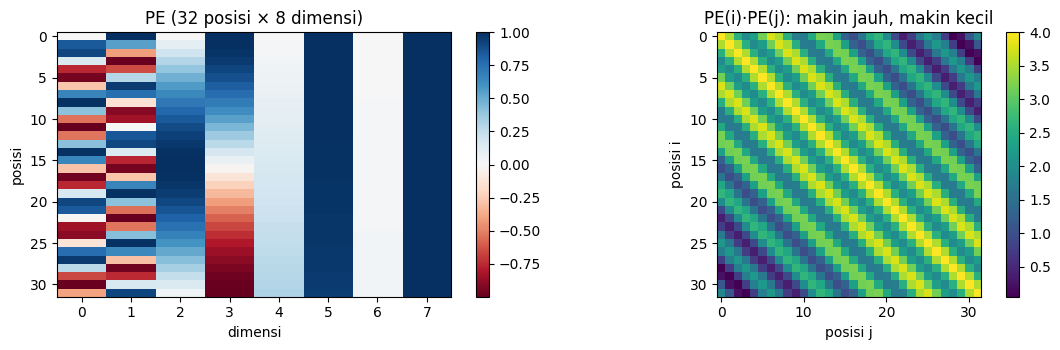

In [7]:
class SinusoidalPositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=512):
        super().__init__()
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(max_len).unsqueeze(1).float()
        div = torch.exp(torch.arange(0, d_model, 2).float() * (-math.log(10000.0) / d_model))
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))     # buffer: bukan parameter, tidak dilatih

    def forward(self, x):                               # x: (B,T,d_model)
        return x + self.pe[:, : x.size(1)]

pe_layer = SinusoidalPositionalEncoding(8, max_len=64)
pe4 = pe_layer.pe[0, :4]
print("shape PE (T=4, d_model=8):", tuple(pe4.shape), "| buffer penuh:", tuple(pe_layer.pe.shape))
print(pe4)

# verifikasi terhadap rumus untuk pos=1: dimensi (0,1) pakai 1/10000^0=1, (2,3) pakai 1/10, (4,5) pakai 1/100, (6,7) pakai 1/1000
pos = 1.0
expected = []
for i in range(4):
    a = pos / (10000 ** (2 * i / 8))
    expected += [math.sin(a), math.cos(a)]
assert torch.allclose(pe4[1], torch.tensor(expected), atol=1e-6)
assert torch.allclose(pe4[0], torch.tensor([0., 1.] * 4))        # pos 0 -> sin=0, cos=1
print("\nOK: nilai PE sama dengan rumus (pos=0 dan pos=1)")

x0 = torch.zeros(2, 4, 8)
print("shape setelah x + PE:", tuple(pe_layer(x0).shape))

# visualisasi
P = pe_layer.pe[0, :32].numpy()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
im = ax[0].imshow(P, aspect="auto", cmap="RdBu"); ax[0].set_title("PE (32 posisi × 8 dimensi)")
ax[0].set_xlabel("dimensi"); ax[0].set_ylabel("posisi"); plt.colorbar(im, ax=ax[0])
sim = P @ P.T
im2 = ax[1].imshow(sim, cmap="viridis"); ax[1].set_title("PE(i)·PE(j): makin jauh, makin kecil")
ax[1].set_xlabel("posisi j"); ax[1].set_ylabel("posisi i"); plt.colorbar(im2, ax=ax[1])
plt.tight_layout(); plt.show()

**Fungsi positional encoding.** Attention bersifat *permutation-equivariant*: tanpa informasi posisi, "anjing menggigit manusia" dan "manusia menggigit anjing" memberi himpunan representasi yang sama. Positional encoding ditambahkan ke embedding token sehingga setiap posisi punya "sidik jari" unik. Pada versi sinusoidal, frekuensi tiap pasangan dimensi berbeda (dari cepat ke lambat), sehingga kombinasinya mengkode posisi absolut, dan karena $PE_{pos+k}$ adalah transformasi linear (rotasi) dari $PE_{pos}$, model mudah mempelajari relasi jarak relatif.

## 5. Blok Transformer

Susunan (post-LN seperti makalah 2017):

```
x -> MHA -> +x -> LayerNorm -> FFN -> +(masukan FFN) -> LayerNorm -> keluaran
```
FFN: `Linear(d_model, d_ff) -> ReLU -> Linear(d_ff, d_model)` dengan $d_{ff}=16$.

In [8]:
class FeedForward(nn.Module):
    def __init__(self, d_model=8, d_ff=16, dropout=0.0):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(d_model, d_ff), nn.ReLU(), nn.Dropout(dropout), nn.Linear(d_ff, d_model))
    def forward(self, x): return self.net(x)

class TransformerBlock(nn.Module):
    def __init__(self, d_model=8, h=2, d_ff=16, dropout=0.0):
        super().__init__()
        self.mha = MultiHeadAttention(d_model, h)
        self.ln1 = nn.LayerNorm(d_model)
        self.ffn = FeedForward(d_model, d_ff, dropout)
        self.ln2 = nn.LayerNorm(d_model)
        self.drop = nn.Dropout(dropout)

    def forward(self, x, mask=None, trace=None):
        a, w = self.mha(x, mask)
        h1 = self.ln1(x + self.drop(a))             # residual + LayerNorm
        f = self.ffn(h1)
        out = self.ln2(h1 + self.drop(f))           # residual + LayerNorm
        if trace is not None:
            trace.update(mha_out=a, after_ln1=h1, ffn_out=f, block_out=out)
        return out, w

set_seed()
block = TransformerBlock(8, 2, 16)
x = torch.randn(2, 4, 8)
trace = {}
y, w = block(x, causal, trace)
print("input      :", tuple(x.shape))
for k_, v_ in trace.items():
    print(f"{k_:10s} :", tuple(v_.shape))
print("bobot attn :", tuple(w.shape))
assert y.shape == x.shape
# LayerNorm: rata-rata ~0 dan std ~1 per token (gamma=1,beta=0 saat inisialisasi)
print("mean per token ~0:", y.mean(-1).abs().max().item() < 1e-5, "| std per token ~1:", torch.allclose(y.std(-1, unbiased=False), torch.ones(2, 4), atol=1e-3))

input      : (2, 4, 8)
mha_out    : (2, 4, 8)
after_ln1  : (2, 4, 8)
ffn_out    : (2, 4, 8)
block_out  : (2, 4, 8)
bobot attn : (2, 2, 4, 4)
mean per token ~0: True | std per token ~1: True


## 6. Uji Fungsional: klasifikasi sekuens dua kelas

**Tugas (sintetis, bergantung pada urutan):** setiap sekuens berisi token A (id 1) dan token B (id 2) tepat satu kali, sisanya token pengisi acak (id 3-9). Panjang sekuens acak 6-8 dan sisanya di-padding dengan PAD (id 0).

- Kelas **1** jika A muncul **sebelum** B, kelas **0** jika sebaliknya.

Karena komposisi token kedua kelas identik, model **harus** memakai informasi posisi (positional encoding) dan attention untuk menjawabnya. Mean pooling bag-of-words saja akan berada di sekitar 50%.

In [9]:
PAD, A_TOK, B_TOK, VOCAB, MAXLEN = 0, 1, 2, 10, 8

def make_dataset(n, seed):
    rng = np.random.default_rng(seed)
    X = np.zeros((n, MAXLEN), dtype=np.int64); y = np.zeros(n, dtype=np.int64)
    for i in range(n):
        L = rng.integers(6, MAXLEN + 1)
        seq = rng.integers(3, VOCAB, size=L)
        pa, pb = rng.choice(L, size=2, replace=False)
        seq[pa], seq[pb] = A_TOK, B_TOK
        X[i, :L] = seq; y[i] = int(pa < pb)
    return torch.from_numpy(X), torch.from_numpy(y)

Xtr, ytr = make_dataset(3000, 1)
Xva, yva = make_dataset(500, 2)
Xte, yte = make_dataset(500, 3)
print("train/val/test:", len(Xtr), len(Xva), len(Xte), "| proporsi kelas 1 (train):", ytr.float().mean().item())
print("contoh:", Xtr[0].tolist(), "-> label", ytr[0].item())

class TinyTransformerClassifier(nn.Module):
    def __init__(self, vocab=VOCAB, d_model=8, h=2, d_ff=16, n_classes=2, dropout=0.0):
        super().__init__()
        self.d_model = d_model
        self.emb = nn.Embedding(vocab, d_model, padding_idx=PAD)
        self.pos = SinusoidalPositionalEncoding(d_model, max_len=64)
        self.block = TransformerBlock(d_model, h, d_ff, dropout)
        self.head = nn.Linear(d_model, n_classes)

    def forward(self, tokens, return_attn=False):
        valid = tokens != PAD                                        # (B,T)
        mask = valid[:, None, None, :]                               # padding mask (B,1,1,T)
        x = self.pos(self.emb(tokens) * math.sqrt(self.d_model))     # (B,T,d)
        x, w = self.block(x, mask)                                   # (B,T,d)
        vf = valid.unsqueeze(-1).float()
        pooled = (x * vf).sum(1) / vf.sum(1)                         # mean pooling hanya token valid
        logits = self.head(pooled)                                   # (B,2)
        return (logits, w) if return_attn else logits

set_seed()
model = TinyTransformerClassifier()
n_params = sum(p.numel() for p in model.parameters())
print(model)
print("\nTotal parameter:", n_params)

train/val/test: 3000 500 500 | proporsi kelas 1 (train): 0.5006666779518127
contoh: [6, 1, 2, 3, 4, 8, 9, 0] -> label 1
TinyTransformerClassifier(
  (emb): Embedding(10, 8, padding_idx=0)
  (pos): SinusoidalPositionalEncoding()
  (block): TransformerBlock(
    (mha): MultiHeadAttention(
      (W_q): Linear(in_features=8, out_features=8, bias=True)
      (W_k): Linear(in_features=8, out_features=8, bias=True)
      (W_v): Linear(in_features=8, out_features=8, bias=True)
      (W_o): Linear(in_features=8, out_features=8, bias=True)
    )
    (ln1): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
    (ffn): FeedForward(
      (net): Sequential(
        (0): Linear(in_features=8, out_features=16, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.0, inplace=False)
        (3): Linear(in_features=16, out_features=8, bias=True)
      )
    )
    (ln2): LayerNorm((8,), eps=1e-05, elementwise_affine=True)
    (drop): Dropout(p=0.0, inplace=False)
  )
  (head): Linear(in_features=8, ou

Konfigurasi: {'vocab': 10, 'd_model': 8, 'h': 2, 'd_ff': 16, 'layers': 1, 'dropout': 0.0, 'optimizer': 'Adam', 'lr': 0.003, 'batch': 64, 'epochs': 60, 'params': 698} 

epoch   1 | train loss 0.6752 | val loss 0.5969 | val acc 0.726
epoch   5 | train loss 0.0727 | val loss 0.0231 | val acc 0.998
epoch  10 | train loss 0.0014 | val loss 0.0015 | val acc 1.000
epoch  15 | train loss 0.0005 | val loss 0.0007 | val acc 1.000
epoch  20 | train loss 0.0003 | val loss 0.0004 | val acc 1.000
epoch  25 | train loss 0.0002 | val loss 0.0003 | val acc 1.000
epoch  30 | train loss 0.0001 | val loss 0.0002 | val acc 1.000
epoch  35 | train loss 0.0001 | val loss 0.0002 | val acc 1.000
epoch  40 | train loss 0.0001 | val loss 0.0001 | val acc 1.000
epoch  45 | train loss 0.0001 | val loss 0.0001 | val acc 1.000
epoch  50 | train loss 0.0000 | val loss 0.0001 | val acc 1.000
epoch  55 | train loss 0.0000 | val loss 0.0001 | val acc 1.000
epoch  60 | train loss 0.0000 | val loss 0.0001 | val acc 1.000


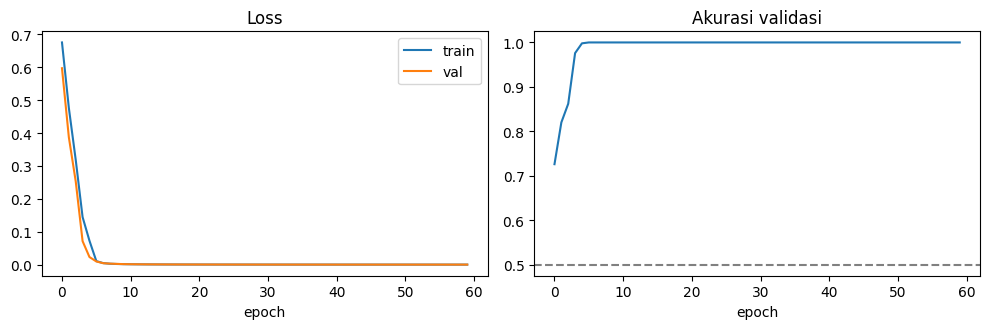

In [10]:
@torch.no_grad()
def evaluate(model, X, y):
    model.eval()
    logits = model(X)
    return F.cross_entropy(logits, y).item(), (logits.argmax(-1) == y).float().mean().item()

def train(model, epochs=60, bs=64, lr=3e-3, log_every=5):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "val_loss": [], "val_acc": []}
    for ep in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(len(Xtr)); tot = 0.0
        for i in range(0, len(Xtr), bs):
            idx = perm[i:i + bs]
            loss = F.cross_entropy(model(Xtr[idx]), ytr[idx])
            opt.zero_grad(); loss.backward(); opt.step()
            tot += loss.item() * len(idx)
        vl, va = evaluate(model, Xva, yva)
        hist["train_loss"].append(tot / len(Xtr)); hist["val_loss"].append(vl); hist["val_acc"].append(va)
        if ep % log_every == 0 or ep == 1:
            print(f"epoch {ep:3d} | train loss {hist['train_loss'][-1]:.4f} | val loss {vl:.4f} | val acc {va:.3f}")
    return hist

CONFIG = dict(vocab=VOCAB, d_model=8, h=2, d_ff=16, layers=1, dropout=0.0, optimizer="Adam", lr=3e-3, batch=64, epochs=60, params=n_params)
print("Konfigurasi:", CONFIG, "\n")
set_seed()
model = TinyTransformerClassifier()
hist = train(model, epochs=CONFIG["epochs"], bs=CONFIG["batch"], lr=CONFIG["lr"])

te_loss, te_acc = evaluate(model, Xte, yte)
print(f"\nHASIL TEST: loss {te_loss:.4f} | akurasi {te_acc:.3f}  (acak = 0.500)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(hist["train_loss"], label="train"); ax[0].plot(hist["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend(); ax[0].set_xlabel("epoch")
ax[1].plot(hist["val_acc"]); ax[1].axhline(0.5, ls="--", c="gray"); ax[1].set_title("Akurasi validasi"); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.show()

In [11]:
# Ablasi singkat: tanpa positional encoding, model tidak bisa membedakan "A sebelum B" dari "B sebelum A"
class NoPE(SinusoidalPositionalEncoding):
    def forward(self, x): return x
set_seed()
m_nope = TinyTransformerClassifier(); m_nope.pos = NoPE(8, 64)
print("Ablasi tanpa positional encoding:")
h2 = train(m_nope, epochs=CONFIG["epochs"], log_every=20)
print("Akurasi test tanpa PE:", round(evaluate(m_nope, Xte, yte)[1], 3), "| dengan PE:", round(te_acc, 3))

Ablasi tanpa positional encoding:
epoch   1 | train loss 0.6960 | val loss 0.6962 | val acc 0.498
epoch  20 | train loss 0.6871 | val loss 0.6978 | val acc 0.472
epoch  40 | train loss 0.6832 | val loss 0.6987 | val acc 0.512
epoch  60 | train loss 0.6810 | val loss 0.6997 | val acc 0.524
Akurasi test tanpa PE: 0.524 | dengan PE: 1.0


## 7. Verifikasi Implementasi

### 7.1 Pemeriksaan shape pada setiap tahap (B = 2, T = 4, d_model = 8, h = 2)

In [12]:
B, T, D, H = 2, 4, 8, 2
set_seed()
m = MultiHeadAttention(D, H)
x = torch.randn(B, T, D)
Q, Kk, Vv = m.W_q(x), m.W_k(x), m.W_v(x)
Qh, Kh, Vh = m.split_heads(Q), m.split_heads(Kk), m.split_heads(Vv)
scores = Qh @ Kh.transpose(-2, -1) / math.sqrt(m.d_k)
ctx, wts, _ = scaled_dot_product_attention(Qh, Kh, Vh)
merged = ctx.transpose(1, 2).contiguous().view(B, T, D)
final, _ = m(x)

rows = [
    ("input x",                         x,       (B, T, D)),
    ("Q = x W_q (sebelum split)",       Q,       (B, T, D)),
    ("query per head",                  Qh,      (B, H, T, D // H)),
    ("key per head",                    Kh,      (B, H, T, D // H)),
    ("value per head",                  Vh,      (B, H, T, D // H)),
    ("matriks skor QK^T/sqrt(d_k)",     scores,  (B, H, T, T)),
    ("bobot attention (softmax)",       wts,     (B, H, T, T)),
    ("konteks per head (w @ V)",        ctx,     (B, H, T, D // H)),
    ("gabungan head (concat)",          merged,  (B, T, D)),
    ("keluaran akhir MHA (W_o)",        final,   (B, T, D)),
]
print(f"{'tensor':36s} {'shape program':18s} {'shape harapan':18s} status")
for name, t, exp in rows:
    ok = tuple(t.shape) == exp
    assert ok, name
    print(f"{name:36s} {str(tuple(t.shape)):18s} {str(exp):18s} {'OK' if ok else 'SALAH'}")

tensor                               shape program      shape harapan      status
input x                              (2, 4, 8)          (2, 4, 8)          OK
Q = x W_q (sebelum split)            (2, 4, 8)          (2, 4, 8)          OK
query per head                       (2, 2, 4, 4)       (2, 2, 4, 4)       OK
key per head                         (2, 2, 4, 4)       (2, 2, 4, 4)       OK
value per head                       (2, 2, 4, 4)       (2, 2, 4, 4)       OK
matriks skor QK^T/sqrt(d_k)          (2, 2, 4, 4)       (2, 2, 4, 4)       OK
bobot attention (softmax)            (2, 2, 4, 4)       (2, 2, 4, 4)       OK
konteks per head (w @ V)             (2, 2, 4, 4)       (2, 2, 4, 4)       OK
gabungan head (concat)               (2, 4, 8)          (2, 4, 8)          OK
keluaran akhir MHA (W_o)             (2, 4, 8)          (2, 4, 8)          OK


### 7.2 Jumlah parameter setiap komponen (manual vs program)

In [13]:
set_seed()
model = TinyTransformerClassifier()
manual = {
    "emb (embedding 10x8)":        10 * 8,
    "pos (sinusoidal)":            0,                           # buffer, bukan parameter
    "block.mha (4 x (8*8+8))":     4 * (8 * 8 + 8),
    "block.ln1 (gamma+beta)":      2 * 8,
    "block.ffn (8*16+16 + 16*8+8)": (8 * 16 + 16) + (16 * 8 + 8),
    "block.ln2 (gamma+beta)":      2 * 8,
    "head (8*2+2)":                8 * 2 + 2,
}
prog = {
    "emb (embedding 10x8)":        sum(p.numel() for p in model.emb.parameters()),
    "pos (sinusoidal)":            sum(p.numel() for p in model.pos.parameters()),
    "block.mha (4 x (8*8+8))":     sum(p.numel() for p in model.block.mha.parameters()),
    "block.ln1 (gamma+beta)":      sum(p.numel() for p in model.block.ln1.parameters()),
    "block.ffn (8*16+16 + 16*8+8)": sum(p.numel() for p in model.block.ffn.parameters()),
    "block.ln2 (gamma+beta)":      sum(p.numel() for p in model.block.ln2.parameters()),
    "head (8*2+2)":                sum(p.numel() for p in model.head.parameters()),
}
print(f"{'komponen':32s} {'manual':>7s} {'program':>8s}  status")
for k_ in manual:
    assert manual[k_] == prog[k_], k_
    print(f"{k_:32s} {manual[k_]:7d} {prog[k_]:8d}  OK")
tot_m, tot_p = sum(manual.values()), sum(p.numel() for p in model.parameters())
print(f"{'TOTAL':32s} {tot_m:7d} {tot_p:8d}  {'OK' if tot_m == tot_p else 'SALAH'}")
assert tot_m == tot_p == 698
tb = sum(p.numel() for p in model.block.parameters())
print("\nSatu blok transformer saja:", tb, "(= 288 + 16 + 280 + 16)")
assert tb == 600

komponen                          manual  program  status
emb (embedding 10x8)                  80       80  OK
pos (sinusoidal)                       0        0  OK
block.mha (4 x (8*8+8))              288      288  OK
block.ln1 (gamma+beta)                16       16  OK
block.ffn (8*16+16 + 16*8+8)         280      280  OK
block.ln2 (gamma+beta)                16       16  OK
head (8*2+2)                          18       18  OK
TOTAL                                698      698  OK

Satu blok transformer saja: 600 (= 288 + 16 + 280 + 16)


### 7.3 Setiap baris attention berjumlah 1, dan 7.4 pengujian padding mask serta causal mask

In [14]:
set_seed()
B, T = 3, 6
x = torch.randn(B, T, 8)
lengths = torch.tensor([6, 4, 2])
pad_mask, causal = make_padding_mask(lengths, T), make_causal_mask(T)
tests = {"tanpa mask": None, "padding": pad_mask, "causal": causal, "padding+causal": pad_mask & causal}

for name, mk in tests.items():
    _, w = mha(x, mk)
    allowed = torch.ones_like(w, dtype=torch.bool) if mk is None else mk.expand_as(w)
    # (a) baris dengan >= 1 posisi valid berjumlah 1
    valid_rows = allowed.any(-1)
    s = w.sum(-1)
    assert torch.allclose(s[valid_rows], torch.ones_like(s[valid_rows]), atol=1e-6), name
    # (b) bobot posisi terlarang tepat nol
    forbidden_max = w[~allowed].max().item() if (~allowed).any() else 0.0
    assert forbidden_max == 0.0, name
    print(f"{name:15s} | jumlah baris min/max = {s.min().item():.6f}/{s.max().item():.6f} | bobot terlarang maks = {forbidden_max} | OK")

# (c) causal: mengubah token MASA DEPAN tidak boleh mengubah keluaran posisi sebelumnya
set_seed()
blk = TransformerBlock(8, 2, 16).eval()
x = torch.randn(1, 6, 8)
x_mod = x.clone(); x_mod[:, 4:] = torch.randn(1, 2, 8)               # ubah posisi 4,5
y1, _ = blk(x, make_causal_mask(6)); y2, _ = blk(x_mod, make_causal_mask(6))
assert torch.allclose(y1[:, :4], y2[:, :4], atol=1e-6) and not torch.allclose(y1[:, 4:], y2[:, 4:])
print("causal: posisi 0-3 tidak berubah ketika posisi 4-5 diubah | OK")
y3, _ = blk(x, None); y4, _ = blk(x_mod, None)
assert not torch.allclose(y3[:, :4], y4[:, :4], atol=1e-6)
print("tanpa causal: posisi 0-3 ikut berubah (kebocoran masa depan) | terbukti")

# (d) padding: isi token PAD tidak boleh mempengaruhi posisi valid
x = torch.randn(1, 6, 8); pm = make_padding_mask(torch.tensor([3]), 6)
x_mod = x.clone(); x_mod[:, 3:] = torch.randn(1, 3, 8)
y1, _ = blk(x, pm); y2, _ = blk(x_mod, pm)
assert torch.allclose(y1[:, :3], y2[:, :3], atol=1e-6)
print("padding: isi posisi PAD diubah, posisi valid tidak berubah | OK")

tanpa mask      | jumlah baris min/max = 1.000000/1.000000 | bobot terlarang maks = 0.0 | OK
padding         | jumlah baris min/max = 1.000000/1.000000 | bobot terlarang maks = 0.0 | OK
causal          | jumlah baris min/max = 1.000000/1.000000 | bobot terlarang maks = 0.0 | OK
padding+causal  | jumlah baris min/max = 1.000000/1.000000 | bobot terlarang maks = 0.0 | OK
causal: posisi 0-3 tidak berubah ketika posisi 4-5 diubah | OK
tanpa causal: posisi 0-3 ikut berubah (kebocoran masa depan) | terbukti
padding: isi posisi PAD diubah, posisi valid tidak berubah | OK


### 7.5 Bukti model dapat meng-overfit satu batch kecil

awal : loss 0.6588 (ln2 = 0.6931)
step    1 | loss 0.6588 | acc 0.688
step   50 | loss 0.0246 | acc 1.000
step  100 | loss 0.0034 | acc 1.000
step  200 | loss 0.0011 | acc 1.000
step  300 | loss 0.0005 | acc 1.000
step  500 | loss 0.0002 | acc 1.000
step  750 | loss 0.0001 | acc 1.000
step 1000 | loss 0.0000 | acc 1.000

akhir: loss 0.00003 | akurasi 1.000
OK: model berhasil menghafal satu batch (loss turun mendekati 0, akurasi 100%)


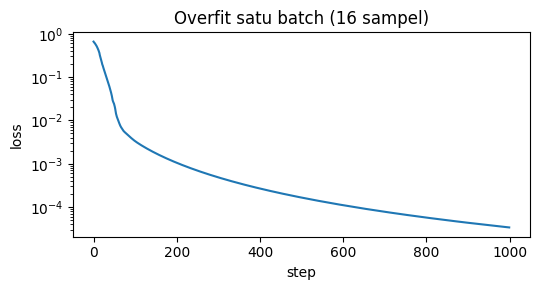

In [15]:
set_seed()
idx = torch.randperm(len(Xtr))[:16]
xb, yb = Xtr[idx], ytr[idx]                        # SATU batch kecil: 16 sampel, tidak diganti-ganti
m_of = TinyTransformerClassifier(dropout=0.0)
opt = torch.optim.Adam(m_of.parameters(), lr=1e-2)

with torch.no_grad():
    l0 = F.cross_entropy(m_of(xb), yb).item()
print(f"awal : loss {l0:.4f} (ln2 = {math.log(2):.4f})")

losses = []
for step in range(1, 1001):
    m_of.train()
    logits = m_of(xb)
    loss = F.cross_entropy(logits, yb)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if step in (1, 50, 100, 200, 300, 500, 750, 1000):
        print(f"step {step:4d} | loss {loss.item():.4f} | acc {(logits.argmax(-1) == yb).float().mean().item():.3f}")

m_of.eval()
with torch.no_grad():
    lf = F.cross_entropy(m_of(xb), yb).item(); af = (m_of(xb).argmax(-1) == yb).float().mean().item()
print(f"\nakhir: loss {lf:.5f} | akurasi {af:.3f}")
assert lf < 0.05 and af == 1.0, "gagal overfit satu batch"
print("OK: model berhasil menghafal satu batch (loss turun mendekati 0, akurasi 100%)")

plt.figure(figsize=(5.5, 3)); plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss")
plt.title("Overfit satu batch (16 sampel)"); plt.tight_layout(); plt.show()

In [16]:
print("=" * 60)
print("RINGKASAN VERIFIKASI")
print("=" * 60)
print("[OK] 1. scaled dot-product attention = hitung manual [0.6225, 0.3775]")
print("[OK] 2. jumlah parameter MHA manual 288 = program 288; model total 698")
print("[OK] 3. MHA sama dengan nn.MultiheadAttention (output dan bobot)")
print("[OK] 4. shape tiap tahap sesuai (7.1)")
print("[OK] 5. setiap baris valid berjumlah 1 setelah softmax")
print("[OK] 6. padding mask & causal mask: bobot terlarang = 0, tidak ada kebocoran")
print("[OK] 7. overfit satu batch: loss ~0, akurasi 100%")
print(f"[OK] 8. model kecil: akurasi test {te_acc:.3f} (acak 0.500)")

RINGKASAN VERIFIKASI
[OK] 1. scaled dot-product attention = hitung manual [0.6225, 0.3775]
[OK] 2. jumlah parameter MHA manual 288 = program 288; model total 698
[OK] 3. MHA sama dengan nn.MultiheadAttention (output dan bobot)
[OK] 4. shape tiap tahap sesuai (7.1)
[OK] 5. setiap baris valid berjumlah 1 setelah softmax
[OK] 6. padding mask & causal mask: bobot terlarang = 0, tidak ada kebocoran
[OK] 7. overfit satu batch: loss ~0, akurasi 100%
[OK] 8. model kecil: akurasi test 1.000 (acak 0.500)


## 8. Jawaban Pertanyaan Analisis

### 1. Shape tensor (d_model = 8, h = 2, T = 4, B = 2), dengan d_k = 4

| Tensor | Shape |
|---|---|
| Input $x$ | (2, 4, 8) |
| Query / Key / Value setelah proyeksi linear | (2, 4, 8) |
| Query / Key / Value per head | (2, 2, 4, 4) |
| Matriks skor $QK^\top/\sqrt{d_k}$ (dan bobot attention) | (2, 2, 4, 4) |
| Konteks per head | (2, 2, 4, 4) |
| Keluaran akhir (setelah concat dan $W_O$) | (2, 4, 8) |

Semuanya sudah diverifikasi dengan `assert` pada 7.1.

### 2. Mengapa skor dibagi $\sqrt{d_k}$?

Jika komponen $q$ dan $k$ bebas dengan rata-rata 0 dan varians 1, maka $q\cdot k=\sum_{i=1}^{d_k}q_ik_i$ memiliki varians $d_k$ (simpangan baku $\sqrt{d_k}$). Dengan membagi $\sqrt{d_k}$, varians skor kembali ≈ 1 berapa pun dimensi key.

Tanpa pembagian, untuk $d_k$ besar skor menjadi bernilai besar dan softmax menjadi **jenuh**: satu posisi mendapat probabilitas ≈ 1 dan yang lain ≈ 0 (distribusi hampir one-hot, entropi rendah). Pada kondisi itu gradien softmax, $p_i(1-p_i)$ dan $-p_ip_j$, mendekati 0 sehingga pelatihan lambat atau macet. Sel di bawah memperlihatkannya secara numerik.

In [17]:
set_seed()
n, T_ = 2000, 10
print(f"{'d_k':>5s} | {'skala':>7s} | {'std skor':>8s} | {'rata2 max prob':>14s} | {'rata2 entropi':>13s} | {'rata2 sum p(1-p)':>16s}")
for d_k_ in (4, 64, 512):
    q_ = torch.randn(n, 1, d_k_); k_ = torch.randn(n, T_, d_k_)
    raw = (q_ @ k_.transpose(1, 2)).squeeze(1)                    # (n,T)
    for label, sc_ in (("tanpa", raw), ("dibagi", raw / math.sqrt(d_k_))):
        p = torch.softmax(sc_, -1)
        ent = -(p * torch.log(p + 1e-12)).sum(-1).mean().item()
        print(f"{d_k_:5d} | {label:>7s} | {sc_.std().item():8.2f} | {p.max(-1).values.mean().item():14.3f} | {ent:13.3f} | {(p * (1 - p)).sum(-1).mean().item():16.3f}")
print(f"\n(entropi maksimum untuk {T_} posisi = ln({T_}) = {math.log(T_):.3f})")

  d_k |   skala | std skor | rata2 max prob | rata2 entropi | rata2 sum p(1-p)
    4 |   tanpa |     2.02 |          0.496 |         1.425 |            0.639
    4 |  dibagi |     1.01 |          0.306 |         1.942 |            0.808
   64 |   tanpa |     7.94 |          0.864 |         0.349 |            0.192
   64 |  dibagi |     0.99 |          0.317 |         1.931 |            0.807
  512 |   tanpa |    22.80 |          0.953 |         0.115 |            0.068
  512 |  dibagi |     1.01 |          0.322 |         1.919 |            0.804

(entropi maksimum untuk 10 posisi = ln(10) = 2.303)


Pada $d_k=512$ tanpa pembagian, std skor sekitar 22, rata-rata probabilitas maksimum mendekati 1 dan entropi mendekati 0 (softmax hampir one-hot, gradiennya hampir hilang). Dengan pembagian, distribusinya tetap lunak seperti pada $d_k$ kecil.

### 3. Padding mask vs causal mask

- **Padding mask** menutup posisi PAD (token pengisi agar panjang sekuens dalam satu batch sama). Bentuknya bergantung pada panjang tiap sampel, sehingga berbeda per sampel, dan dipakai di model apa pun (encoder maupun decoder) agar PAD tidak "dibaca".
- **Causal mask** menutup semua posisi **masa depan** (segitiga atas), sehingga token $i$ hanya melihat $j\le i$. Bentuknya tetap dan hanya bergantung pada $T$.
- Keduanya dapat digabung dengan operasi AND (7.3, "padding+causal").

**Jika causal mask tidak dipakai pada model autoregresif:** saat pelatihan (teacher forcing) posisi $i$ dapat melihat token target di posisi $i+1, \dots$, yaitu jawaban yang seharusnya diprediksi. Loss turun sangat cepat karena model sekadar menyalin, tetapi saat generasi (token masa depan belum ada) model gagal total. Ada ketidakcocokan antara train dan inferensi. Bukti di 7.3(c): tanpa causal mask, keluaran posisi 0-3 berubah ketika posisi 4-5 diubah (kebocoran).

### 4. Positional encoding: fungsi dan perbandingan

**Fungsi:** attention tidak mengetahui urutan (permutation-equivariant), jadi urutan harus disuntikkan. Positional encoding ditambahkan ke embedding sehingga representasi tiap token memuat posisinya (dibuktikan pada ablasi bagian 6: tanpa PE, tugas "A sebelum B" tidak dapat dipelajari di atas ≈50%).

| | Sinusoidal | Learned embedding |
|---|---|---|
| Parameter | 0 (fungsi tetap) | `max_len × d_model` parameter |
| Panjang di luar data latih | Dapat dihitung untuk posisi sembarang (secara praktis ekstrapolasi terbatas) | Tidak punya embedding untuk posisi > `max_len` |
| Informasi relatif | $PE_{pos+k}$ adalah transformasi linear dari $PE_{pos}$ | Harus dipelajari dari data |
| Fleksibilitas | Terbatas pada pola sin/cos | Dapat menyesuaikan dengan data |
| Penggunaan | Transformer 2017 | BERT, GPT-2 |

Pada makalah asli, kedua pilihan memberi kualitas yang hampir sama.

### 5. Mengapa LayerNorm, bukan BatchNorm?

- **BatchNorm** menghitung statistik lintas batch (dan lintas posisi). Pada data sekuens, panjang berbeda-beda dan terdapat token PAD sehingga statistik tercemar oleh padding dan bergantung pada komposisi batch.
- BatchNorm bergantung pada ukuran batch (tidak stabil pada batch kecil) dan perlu *running statistics* yang berbeda saat training dan inferensi. Pada generasi autoregresif, 1 token per langkah, statistik batch hampir tidak bermakna.
- **LayerNorm** menormalkan fitur **per token** ($d_{model}$ dimensi), bebas dari ukuran batch, panjang sekuens, dan padding, serta berperilaku sama saat training dan inferensi. Bukti kecil: rata-rata ≈ 0 dan std ≈ 1 per token pada Bagian 5.

### 6. Satu kesalahan implementasi dan cara memverifikasi perbaikannya

**Kesalahan:** pada versi naif, baris attention yang seluruh posisinya di-mask (semua $-\infty$) menghasilkan **NaN** setelah softmax (0/0), dan NaN ini merambat ke seluruh loss dan gradien.

**Perbaikan:** `torch.nan_to_num(w, nan=0.0)` setelah softmax, sehingga baris tanpa posisi valid bernilai 0.

**Verifikasi:** sel pada Bagian 3 menunjukkan (a) versi naif menghasilkan NaN, (b) versi perbaikan tidak ada NaN, (c) baris yang punya posisi valid tetap berjumlah 1, dan (d) baris tanpa posisi valid bernilai 0. Semuanya dicek dengan `assert`. Pemeriksaan tambahan di 7.3 mengulang uji jumlah baris dan bobot terlarang untuk empat jenis mask.

### 7. Masalah model recurrent yang ditangani attention

**Masalah:** pada RNN/LSTM, informasi dari token jauh harus melewati banyak langkah berurutan melalui hidden state tunggal. Akibatnya terjadi *vanishing gradient* dan informasi terkompresi pada vektor berukuran tetap (bottleneck), sehingga ketergantungan jarak jauh sulit dipelajari. Perhitungan juga sekuensial dan tidak dapat diparalelkan sepanjang waktu.

**Penanganan oleh attention:** setiap posisi langsung membaca setiap posisi lain dalam satu langkah (jalur gradien sepanjang $O(1)$, bukan $O(T)$) dan seluruh posisi dihitung paralel sebagai perkalian matriks.

**Hubungan dengan implementasi:** matriks skor `(B, h, T, T)` pada `scaled_dot_product_attention` adalah hubungan langsung semua pasangan posisi. Pada tugas klasifikasi bagian 6, token A dan B dapat saling "melihat" langsung walau terpisah beberapa posisi. Karena jalur langsung ini tidak memuat urutan, ia dilengkapi `SinusoidalPositionalEncoding`, dan causal mask menggantikan urutan temporal RNN yang bersifat alami (hanya melihat masa lalu).

### 8. Causal mask vs attention dua arah, dan komponen yang bertahan sejak 2017

| Keluarga | Attention | Konsekuensi |
|---|---|---|
| **Decoder-only** (keluarga GPT, LLaMA) | Causal (satu arah) | Cocok untuk generasi teks autoregresif. Semua posisi dilatih paralel dengan target token berikutnya, dan inferensi dapat memakai KV cache. Representasi token tidak melihat konteks kanan. |
| **Encoder-only** (keluarga BERT) | Dua arah, tanpa causal mask | Representasi tiap token memakai konteks kiri dan kanan sehingga kuat untuk klasifikasi, NER, dan retrieval. Tidak dapat menghasilkan teks token demi token secara langsung (dilatih dengan masked language modelling). |
| **Encoder-decoder** (Transformer 2017, T5) | Encoder dua arah, decoder causal + cross-attention ke encoder | Cocok untuk terjemahan dan peringkasan, yaitu masukan dipahami penuh lalu keluaran dibangkitkan bertahap. |

**Dua komponen yang bertahan sejak transformer 2017:** (1) *multi-head scaled dot-product self-attention* dan (2) *residual connection yang dipasangkan dengan normalisasi layer* di sekitar tiap sub-lapisan (bersama FFN per posisi). Catatan: bentuknya sudah berkembang (pre-LN, RMSNorm, GQA, RoPE, dan lain-lain), tetapi konsep dasarnya sama dengan yang diimplementasikan di sini.

### 9. Pengayaan: Rotary Position Embedding (RoPE)

**Gagasan:** pada implementasi ini, posisi **ditambahkan** ke embedding input sekali di awal (sinusoidal absolut). Pada RoPE, posisi tidak ditambahkan. Vektor $q$ dan $k$ pada tiap layer **diputar** per pasangan dimensi dengan sudut $m\theta_i$ (m = posisi). Hasilnya, dot product $\langle R_m q, R_n k\rangle$ hanya bergantung pada selisih posisi $m-n$.

**Perbaikan dibanding komponen dasar:**
- Informasi posisi **relatif** menjadi sifat langsung dari skor attention, bukan sesuatu yang harus diekstrak oleh jaringan dari penjumlahan.
- Tanpa parameter tambahan, dan diterapkan pada tiap layer sehingga informasi posisi tidak "larut" di lapisan dalam.
- Perilaku terhadap panjang konteks lebih baik. Dengan teknik penskalaan frekuensi (mis. position interpolation), konteks dapat diperpanjang setelah pelatihan. Inilah sebabnya RoPE dipakai di banyak LLM modern.

Sel berikut memverifikasi sifat intinya secara numerik, dan membandingkannya dengan penambahan PE sinusoidal pada input.

In [18]:
def rope(x, pos, base=10000.0):                      # x: (..., d) dengan d genap
    d = x.size(-1)
    inv = base ** (-torch.arange(0, d, 2, dtype=x.dtype) / d)
    ang = pos * inv
    cos, sin = ang.cos(), ang.sin()
    x1, x2 = x[..., 0::2], x[..., 1::2]
    out = torch.empty_like(x)
    out[..., 0::2] = x1 * cos - x2 * sin
    out[..., 1::2] = x1 * sin + x2 * cos
    return out

set_seed()
qv, kv = torch.randn(8).double(), torch.randn(8).double()
print("RoPE: <R_m q, R_n k> untuk pasangan (m,n) dengan selisih m-n = 2 yang sama")
vals = []
for m_, n_ in [(2, 0), (10, 8), (103, 101)]:
    v_ = (rope(qv, float(m_)) @ rope(kv, float(n_))).item(); vals.append(v_)
    print(f"  m={m_:3d}, n={n_:3d} -> {v_:.6f}")
assert max(vals) - min(vals) < 1e-9
print("OK: hasil sama, hanya bergantung pada jarak relatif\n")

pe64 = SinusoidalPositionalEncoding(8, 256).pe[0].double()
print("PE sinusoidal ditambahkan ke input: <(q+PE_m), (k+PE_n)> untuk pasangan yang sama")
vals2 = [((qv + pe64[m_]) @ (kv + pe64[n_])).item() for m_, n_ in [(2, 0), (10, 8), (103, 101)]]
print("  ", [round(v_, 6) for v_ in vals2], "-> berbeda-beda (tidak murni relatif)")

RoPE: <R_m q, R_n k> untuk pasangan (m,n) dengan selisih m-n = 2 yang sama
  m=  2, n=  0 -> -3.413995
  m= 10, n=  8 -> -3.413995
  m=103, n=101 -> -3.413995
OK: hasil sama, hanya bergantung pada jarak relatif

PE sinusoidal ditambahkan ke input: <(q+PE_m), (k+PE_n)> untuk pasangan yang sama
   [-0.629846, -1.124713, -2.100437] -> berbeda-beda (tidak murni relatif)


## Ringkasan artefak

| Artefak | Lokasi di notebook |
|---|---|
| Kode scaled dot-product attention, MHA, positional encoding, blok transformer | Bagian 1, 2, 4, 5 |
| Skrip verifikasi terhadap perhitungan manual | Bagian 1 (attention), 2 (parameter), 4 (PE) |
| Tabel shape dan jumlah parameter | Bagian 7.1 dan 7.2 |
| Bukti padding mask dan causal mask | Bagian 3, 7.3 |
| Bukti overfit satu batch | Bagian 7.5 |
| Hasil pelatihan dan evaluasi model kecil | Bagian 6 |
| Jawaban pertanyaan analisis | Bagian 8 |